# Digital Image Processing Lab — Lab Task 05
## Spatial Filtering and Convolution


**Student Name:** Danial Ayub Mughal  
**Roll Number:** 2024-SE-20   
**Semester:** Fifth  

### Objectives
1. Implement true 2-D convolution from first principles using nested loops, a flipped kernel, reflect padding, and `float64`.
2. Verify the implementation against OpenCV.
3. Generate reproducible Gaussian and salt-and-pepper noise using seed 5.
4. Apply mean, Gaussian, and median filters at 3×3, 5×5, and 7×7.
5. Verify the filtering rules, complete both dry-run calculations, and discuss the results using the notebook figures.



In [1]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Import libraries and load the three test images



Camera: shape=(512, 512), dtype=uint8, range=(0, 255)
Coins: shape=(303, 384), dtype=uint8, range=(1, 252)
Chelsea (grayscale): shape=(300, 451), dtype=uint8, range=(4, 193)


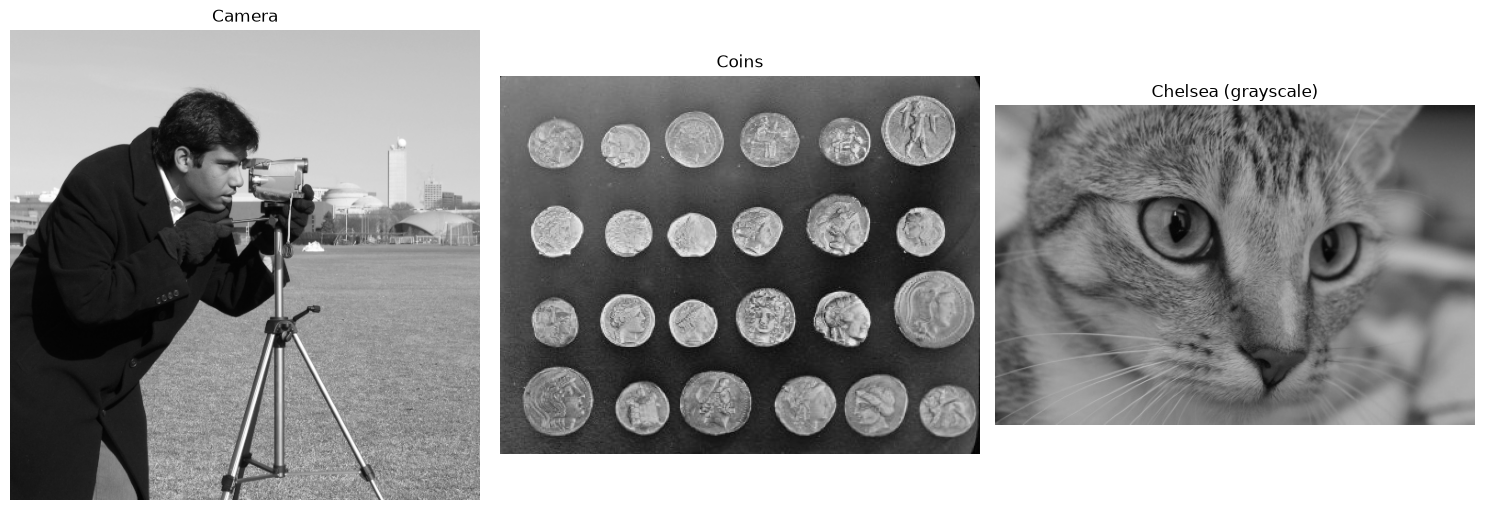

In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data, color, img_as_ubyte

# Load the original test images as grayscale uint8 arrays.
camera_original = data.camera()
coins_original = data.coins()
chelsea_rgb = data.chelsea()
chelsea_original = img_as_ubyte(color.rgb2gray(chelsea_rgb))

images = {
    "Camera": camera_original.copy(),
    "Coins": coins_original.copy(),
    "Chelsea (grayscale)": chelsea_original.copy()
}

for name, img in images.items():
    print(f"{name}: shape={img.shape}, dtype={img.dtype}, range=({img.min()}, {img.max()})")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, img) in zip(axes, images.items()):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

Camera: shape=(512, 512), dtype=uint8, range=(0, 255)
Coins: shape=(303, 384), dtype=uint8, range=(1, 252)
Chelsea (grayscale): shape=(300, 451), dtype=uint8, range=(4, 193)


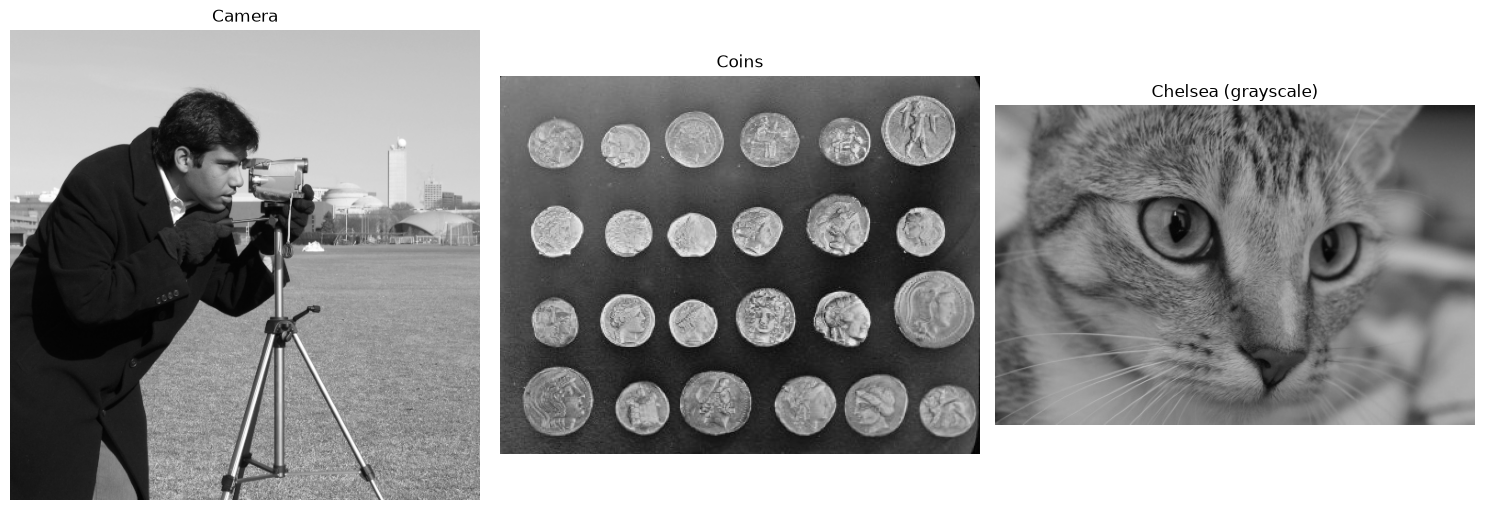

In [3]:

# Load the original test images as grayscale uint8 arrays.
camera_original = data.camera()
coins_original = data.coins()
chelsea_rgb = data.chelsea()
chelsea_original = img_as_ubyte(color.rgb2gray(chelsea_rgb))

images = {
    "Camera": camera_original.copy(),
    "Coins": coins_original.copy(),
    "Chelsea (grayscale)": chelsea_original.copy()
}

for name, img in images.items():
    print(f"{name}: shape={img.shape}, dtype={img.dtype}, range=({img.min()}, {img.max()})")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, img) in zip(axes, images.items()):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Implement 2-D convolution from first principles 



In [4]:
def conv2d_loop(img, kernel):
    """True 2-D convolution with reflect padding and float64 output."""
    image = np.asarray(img, dtype=np.float64)
    filt = np.asarray(kernel, dtype=np.float64)

    if image.ndim != 2 or filt.ndim != 2:
        raise ValueError("Image and kernel must both be 2-D arrays.")
    if filt.shape[0] % 2 == 0 or filt.shape[1] % 2 == 0:
        raise ValueError("Kernel dimensions must be odd.")

    kh, kw = filt.shape
    pad_h, pad_w = kh // 2, kw // 2
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode="reflect")
    flipped_kernel = np.flipud(np.fliplr(filt))

    output = np.zeros(image.shape, dtype=np.float64)
    for row in range(image.shape[0]):
        for col in range(image.shape[1]):
            region = padded[row:row + kh, col:col + kw]
            output[row, col] = np.sum(region * flipped_kernel, dtype=np.float64)
    return output


def to_uint8(img):
    """Round, clip to [0, 255], then convert to uint8."""
    return np.clip(np.rint(img), 0, 255).astype(np.uint8)


# A small example to make the function's output easy to inspect.
example_img = np.array([[10, 20, 30],
                        [40, 50, 60],
                        [70, 80, 90]], dtype=np.uint8)
example_kernel = np.ones((3, 3), dtype=np.float64) / 9
example_result = conv2d_loop(example_img, example_kernel)
print("Output dtype:", example_result.dtype)
print("Output shape:", example_result.shape)
print(np.round(example_result, 3))

Output dtype: float64
Output shape: (3, 3)
[[36.667 40.    43.333]
 [46.667 50.    53.333]
 [56.667 60.    63.333]]


## 3. Verify the custom convolution against OpenCV



In [5]:
verification_image = images["Camera"].astype(np.float64)
verification_kernel = np.ones((3, 3), dtype=np.float64) / 9.0

custom_verification = conv2d_loop(verification_image, verification_kernel)
opencv_verification = cv2.filter2D(
    verification_image, ddepth=cv2.CV_64F,
    kernel=np.flipud(np.fliplr(verification_kernel)),
    borderType=cv2.BORDER_REFLECT_101
)

largest_difference = np.max(np.abs(custom_verification - opencv_verification))
print("Image used:", "Camera")
print("Largest absolute difference:", largest_difference)
print("Agreement within rounding (<= 1e-10):", largest_difference <= 1e-10)

Image used: Camera
Largest absolute difference: 5.684341886080802e-14
Agreement within rounding (<= 1e-10): True


## 4. Create mean and Gaussian kernels; implement the noise functions



In [6]:
def mean_kernel(size):
    if size not in (3, 5, 7):
        raise ValueError("Kernel size must be 3, 5, or 7.")
    return np.ones((size, size), dtype=np.float64) / (size * size)


def gaussian_kernel(size, sigma=None):
    if size not in (3, 5, 7):
        raise ValueError("Kernel size must be 3, 5, or 7.")
    if sigma is None:
        # A common discrete scale for these kernel sizes.
        sigma = size / 6.0
    coords = np.arange(size, dtype=np.float64) - (size - 1) / 2
    xx, yy = np.meshgrid(coords, coords)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    kernel /= kernel.sum()
    return kernel


def add_gaussian_noise(img, sigma=20, seed=5):
    rng = np.random.default_rng(seed)
    noisy = np.asarray(img, dtype=np.float64) + rng.normal(0, sigma, np.asarray(img).shape)
    return to_uint8(noisy)


def add_salt_pepper(img, amount=0.05, seed=5):
    if not 0 <= amount <= 1:
        raise ValueError("amount must be between 0 and 1.")
    rng = np.random.default_rng(seed)
    noisy = np.asarray(img, dtype=np.uint8).copy()
    random_values = rng.random(noisy.shape)
    noisy[random_values < amount / 2] = 0
    noisy[(random_values >= amount / 2) & (random_values < amount)] = 255
    return noisy


for size in (3, 5, 7):
    mk = mean_kernel(size)
    gk = gaussian_kernel(size)
    print(f"{size}x{size} mean-kernel sum: {mk.sum():.12f}")
    print(f"{size}x{size} Gaussian-kernel sum: {gk.sum():.12f}")
    if size == 3:
        print("3x3 Gaussian kernel:")
        print(np.round(gk, 6))

3x3 mean-kernel sum: 1.000000000000
3x3 Gaussian-kernel sum: 1.000000000000
3x3 Gaussian kernel:
[[0.011344 0.08382  0.011344]
 [0.08382  0.619347 0.08382 ]
 [0.011344 0.08382  0.011344]]
5x5 mean-kernel sum: 1.000000000000
5x5 Gaussian-kernel sum: 1.000000000000
7x7 mean-kernel sum: 1.000000000000
7x7 Gaussian-kernel sum: 1.000000000000


## 5. Generate reproducible noisy images 



Camera | Gaussian identical: True | Salt-pepper identical: True
Coins | Gaussian identical: True | Salt-pepper identical: True
Chelsea (grayscale) | Gaussian identical: True | Salt-pepper identical: True


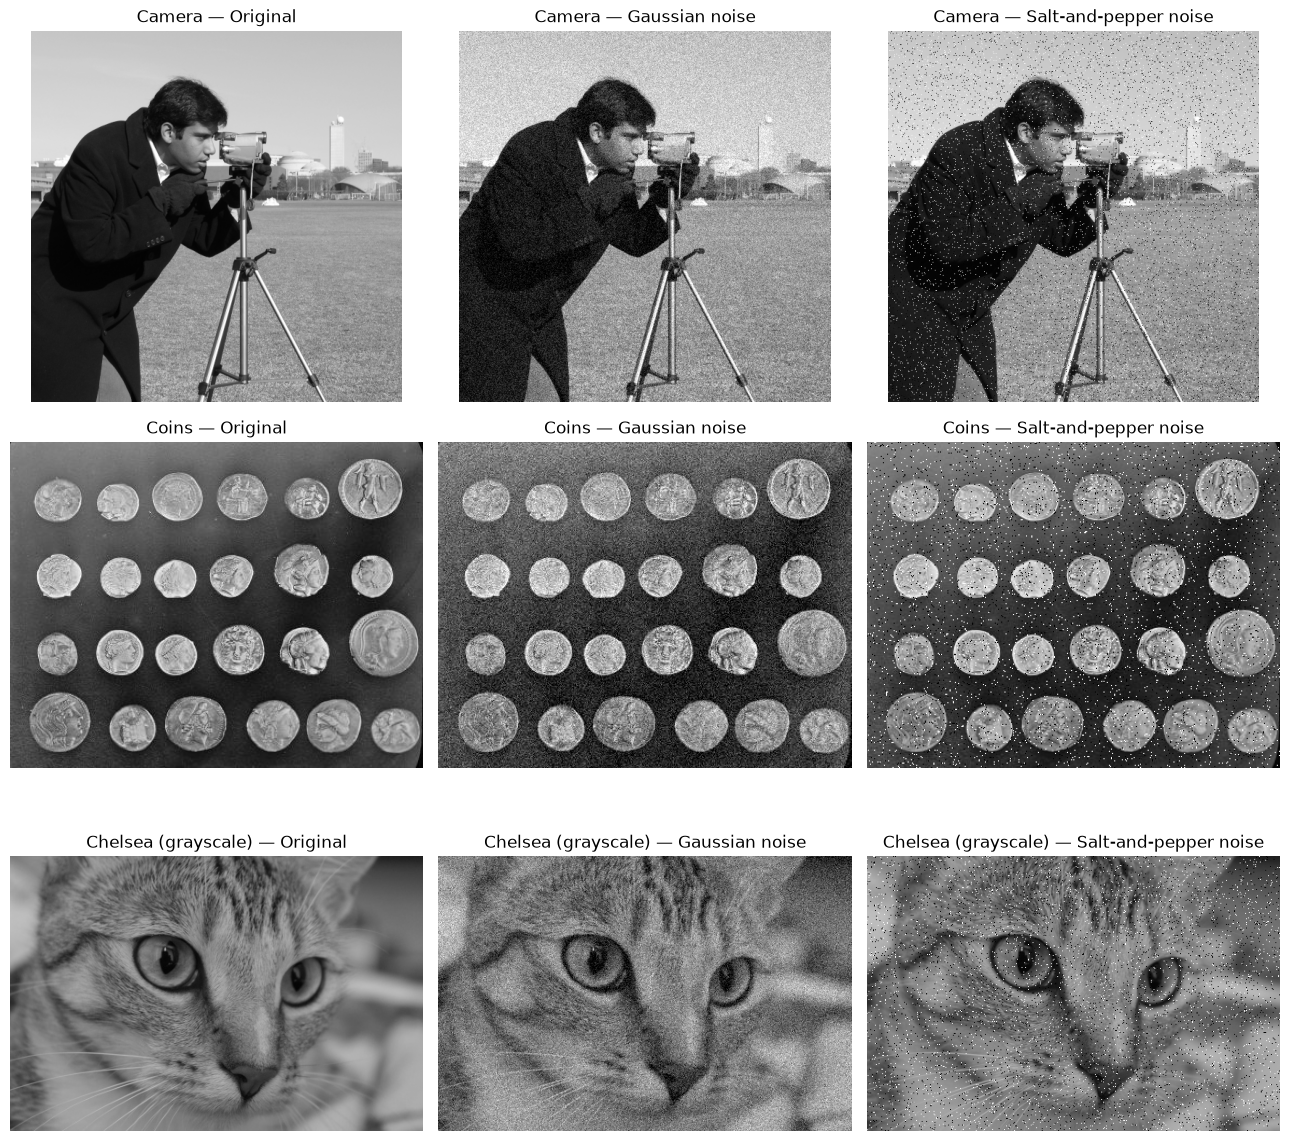

In [7]:
noisy_images = {}
for name, original in images.items():
    noisy_images[name] = {
        "Gaussian noise": add_gaussian_noise(original, sigma=20, seed=5),
        "Salt-and-pepper noise": add_salt_pepper(original, amount=0.05, seed=5)
    }

# Reproducibility checks: same image + same parameters + same seed = identical output.
for name, original in images.items():
    gaussian_again = add_gaussian_noise(original, sigma=20, seed=5)
    sp_again = add_salt_pepper(original, amount=0.05, seed=5)
    print(
        name,
        "| Gaussian identical:", np.array_equal(noisy_images[name]["Gaussian noise"], gaussian_again),
        "| Salt-pepper identical:", np.array_equal(noisy_images[name]["Salt-and-pepper noise"], sp_again)
    )

# Required labeled grid: original, Gaussian noise, salt-and-pepper noise for all three images.
fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for row, (name, original) in enumerate(images.items()):
    panels = [
        (original, f"{name} — Original"),
        (noisy_images[name]["Gaussian noise"], f"{name} — Gaussian noise"),
        (noisy_images[name]["Salt-and-pepper noise"], f"{name} — Salt-and-pepper noise")
    ]
    for col, (img, title) in enumerate(panels):
        axes[row, col].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(title)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

## 6. Apply mean, Gaussian, and median filters (R1–R4)



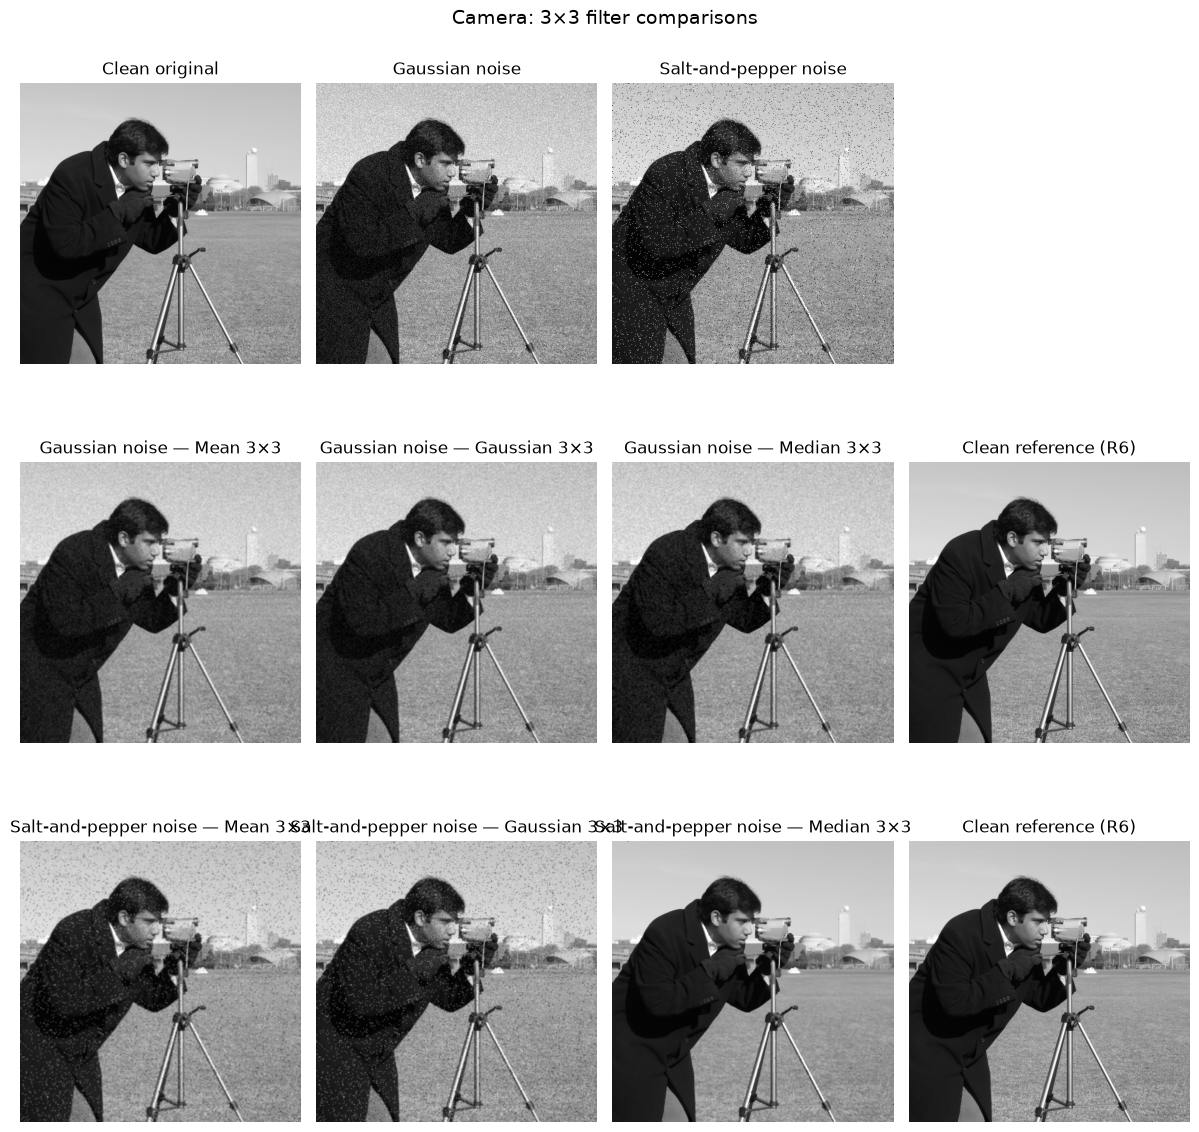

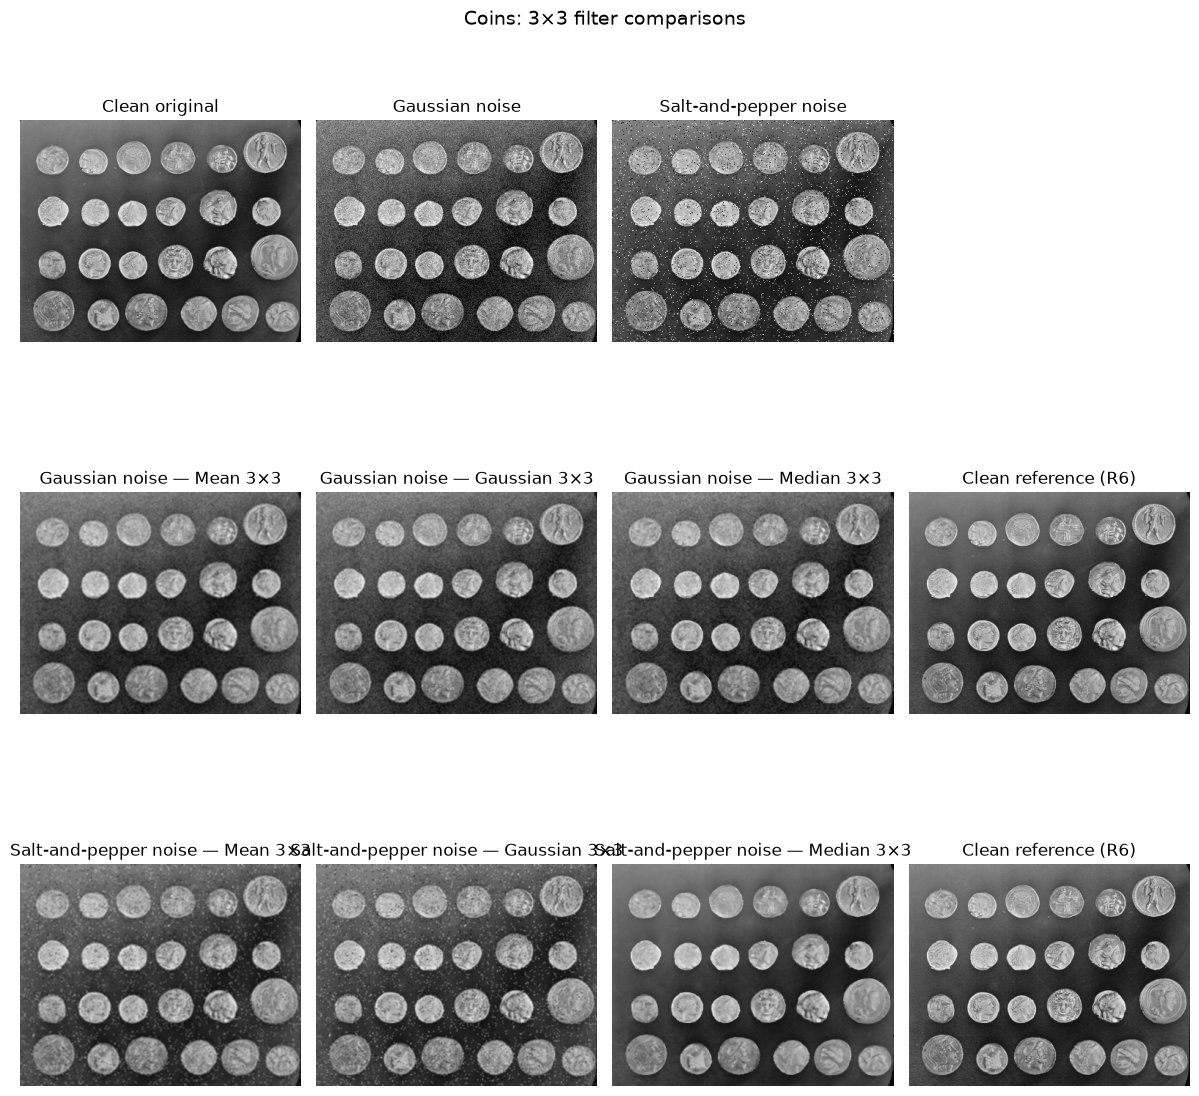

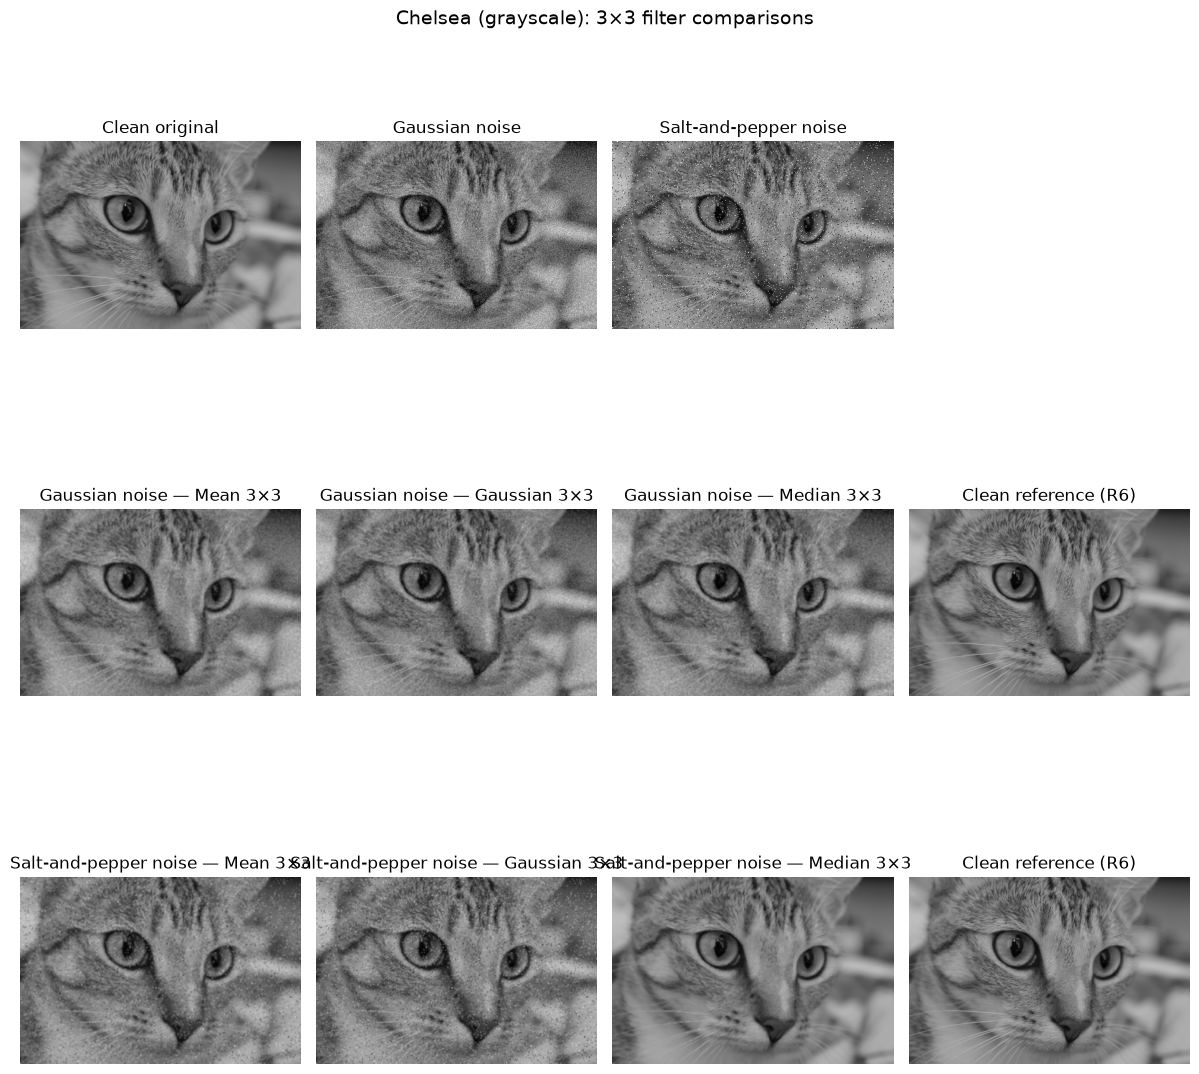

In [8]:
def apply_mean_custom(img, size):
    return to_uint8(conv2d_loop(img, mean_kernel(size)))


def apply_mean_opencv(img, size):
    # OpenCV blur uses the default reflect-101 border.
    result = cv2.blur(np.asarray(img), (size, size), borderType=cv2.BORDER_REFLECT_101)
    return to_uint8(result)


def apply_gaussian(img, size):
    kernel = gaussian_kernel(size)
    result = cv2.GaussianBlur(
        np.asarray(img), (size, size), sigmaX=0, sigmaY=0,
        borderType=cv2.BORDER_REFLECT_101
    )
    return to_uint8(result)


def apply_median_reflect(img, size):
    if size not in (3, 5, 7) or size % 2 == 0:
        raise ValueError("Median kernel size must be an odd value: 3, 5, or 7.")
    pad = size // 2
    padded = np.pad(np.asarray(img, dtype=np.uint8),
                    ((pad, pad), (pad, pad)), mode="reflect")
    filtered = cv2.medianBlur(padded, size)
    return filtered[pad:-pad, pad:-pad]


def apply_filter_set(img, size=3):
    return {
        "Mean": apply_mean_custom(img, size),
        "Gaussian": apply_gaussian(img, size),
        "Median": apply_median_reflect(img, size)
    }


filtered_3x3 = {}
for image_name in images:
    filtered_3x3[image_name] = {}
    for noise_name, noisy in noisy_images[image_name].items():
        filtered_3x3[image_name][noise_name] = apply_filter_set(noisy, 3)

# Labeled grid: each noisy image is compared with all three 3x3 filters.
for image_name in images:
    fig, axes = plt.subplots(3, 4, figsize=(12, 12))
    axes[0, 0].imshow(images[image_name], cmap="gray", vmin=0, vmax=255)
    axes[0, 0].set_title("Clean original")
    axes[0, 0].axis("off")
    for col, noise_name in enumerate(("Gaussian noise", "Salt-and-pepper noise"), start=1):
        axes[0, col].imshow(noisy_images[image_name][noise_name], cmap="gray", vmin=0, vmax=255)
        axes[0, col].set_title(noise_name)
        axes[0, col].axis("off")
    axes[0, 3].axis("off")
    for row, noise_name in enumerate(("Gaussian noise", "Salt-and-pepper noise"), start=1):
        for col, filter_name in enumerate(("Mean", "Gaussian", "Median")):
            axes[row, col].imshow(
                filtered_3x3[image_name][noise_name][filter_name],
                cmap="gray", vmin=0, vmax=255
            )
            axes[row, col].set_title(f"{noise_name} — {filter_name} 3×3")
            axes[row, col].axis("off")
        axes[row, 3].imshow(images[image_name], cmap="gray", vmin=0, vmax=255)
        axes[row, 3].set_title("Clean reference (R6)")
        axes[row, 3].axis("off")
    fig.suptitle(f"{image_name}: 3×3 filter comparisons", fontsize=14)
    plt.tight_layout()
    plt.show()

## 7. Compare kernel sizes 3×3, 5×5, and 7×7 



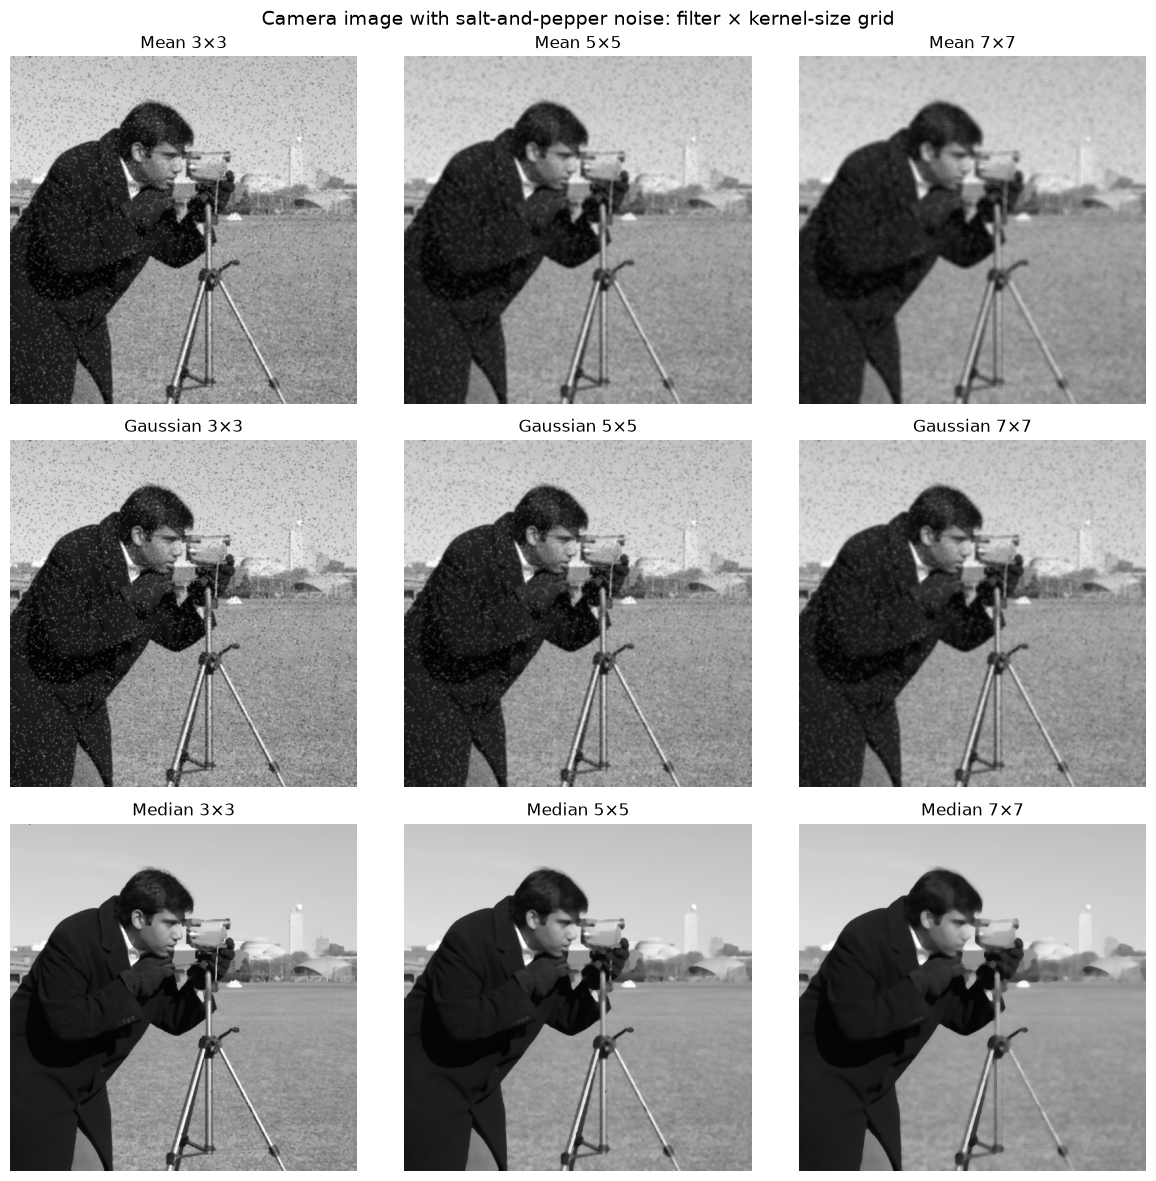

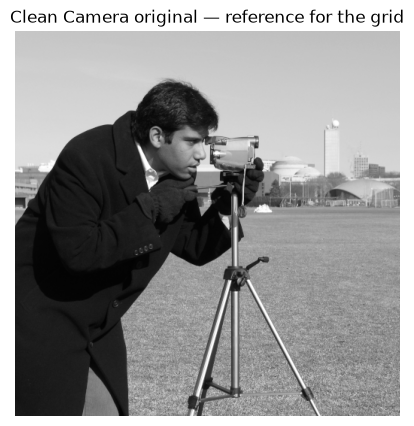

In [9]:
kernel_size_comparison = {}
selected_image_name = "Camera"
selected_noisy = noisy_images[selected_image_name]["Salt-and-pepper noise"]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for row, filter_name in enumerate(("Mean", "Gaussian", "Median")):
    for col, size in enumerate((3, 5, 7)):
        if filter_name == "Mean":
            result = apply_mean_custom(selected_noisy, size)
        elif filter_name == "Gaussian":
            result = apply_gaussian(selected_noisy, size)
        else:
            result = apply_median_reflect(selected_noisy, size)
        kernel_size_comparison[(filter_name, size)] = result
        axes[row, col].imshow(result, cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(f"{filter_name} {size}×{size}")
        axes[row, col].axis("off")
fig.suptitle("Camera image with salt-and-pepper noise: filter × kernel-size grid", fontsize=14)
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 5))
plt.imshow(images[selected_image_name], cmap="gray", vmin=0, vmax=255)
plt.title("Clean Camera original — reference for the grid")
plt.axis("off")
plt.show()

## 8. Rule-compliance checks



In [10]:
# Check output type, range, and shape for all 3x3 outputs.
all_outputs = []
for image_name in images:
    for noise_name in noisy_images[image_name]:
        source = noisy_images[image_name][noise_name]
        for filter_name, output in filtered_3x3[image_name][noise_name].items():
            all_outputs.append((image_name, noise_name, filter_name, source, output))

checks_passed = True
for image_name, noise_name, filter_name, source, output in all_outputs:
    valid = (
        output.dtype == np.uint8
        and output.shape == source.shape
        and output.min() >= 0
        and output.max() <= 255
    )
    checks_passed = checks_passed and valid
    print(f"{image_name} | {noise_name} | {filter_name}: "
          f"dtype={output.dtype}, shape={output.shape}, "
          f"range=({output.min()}, {output.max()}), PASS={valid}")
print("All output checks passed:", checks_passed)

print("\nSmoothing-kernel sums:")
for size in (3, 5, 7):
    print(f"Size {size}: mean={mean_kernel(size).sum():.12f}, "
          f"Gaussian={gaussian_kernel(size).sum():.12f}")

print("\nEven-kernel rejection:")
try:
    cv2.medianBlur(images["Camera"], 4)
except cv2.error as error:
    print("OpenCV rejected cv2.medianBlur(img, 4) as expected.")
    print("Error type:", type(error).__name__)

try:
    apply_median_reflect(images["Camera"], 4)
except ValueError as error:
    print("Our median wrapper rejected size 4 as expected:", error)

Camera | Gaussian noise | Mean: dtype=uint8, shape=(512, 512), range=(0, 254), PASS=True
Camera | Gaussian noise | Gaussian: dtype=uint8, shape=(512, 512), range=(0, 253), PASS=True
Camera | Gaussian noise | Median: dtype=uint8, shape=(512, 512), range=(0, 255), PASS=True
Camera | Salt-and-pepper noise | Mean: dtype=uint8, shape=(512, 512), range=(2, 255), PASS=True
Camera | Salt-and-pepper noise | Gaussian: dtype=uint8, shape=(512, 512), range=(2, 255), PASS=True
Camera | Salt-and-pepper noise | Median: dtype=uint8, shape=(512, 512), range=(0, 255), PASS=True
Coins | Gaussian noise | Mean: dtype=uint8, shape=(303, 384), range=(2, 238), PASS=True
Coins | Gaussian noise | Gaussian: dtype=uint8, shape=(303, 384), range=(1, 241), PASS=True
Coins | Gaussian noise | Median: dtype=uint8, shape=(303, 384), range=(0, 244), PASS=True
Coins | Salt-and-pepper noise | Mean: dtype=uint8, shape=(303, 384), range=(5, 232), PASS=True
Coins | Salt-and-pepper noise | Gaussian: dtype=uint8, shape=(303, 3

## 9. Dry-run Exercise 1 — Spike response

Given the 3×3 neighbourhood

\[
\begin{bmatrix}
40&40&40\\
40&255&40\\
40&40&40
\end{bmatrix}
\]

Calculate the centre output for the 3×3 mean, 3×3 Gaussian, and 3×3 median filters.

### Mean filter
All nine values have weight \(1/9\).

\[
\text{Sum}=8(40)+255=320+255=575
\]
\[
\text{Mean}=575/9=63.8889\approx64
\]

### Gaussian filter
The 3×3 Gaussian kernel is

\[
\frac{1}{16}
\begin{bmatrix}
1&2&1\\
2&4&2\\
1&2&1
\end{bmatrix}
\]

The eight surrounding values have total weight \(1+2+1+2+2+1+2+1=12\), and the centre value has weight 4.

\[
\text{Weighted sum}=40(12)+255(4)=480+1020=1500
\]
\[
\text{Gaussian output}=1500/16=93.75\approx94
\]

### Median filter
Sorted values are eight 40s followed by 255. The middle (fifth) value is 40.

\[
\text{Median}=40
\]

The median returns the background value because one isolated bright spike cannot move the middle value of the sorted neighbourhood.

In [11]:
spike = np.array([[40, 40, 40],
                  [40, 255, 40],
                  [40, 40, 40]], dtype=np.uint8)
mean3 = mean_kernel(3)
gaussian3 = np.array([[1, 2, 1],
                      [2, 4, 2],
                      [1, 2, 1]], dtype=np.float64) / 16

mean_spike = conv2d_loop(spike, mean3)[1, 1]
gaussian_spike = conv2d_loop(spike, gaussian3)[1, 1]
median_spike = np.median(spike)

print("Mean intermediate sum: 8*40 + 255 = ", 8*40 + 255)
print("Mean centre output:", mean_spike)
print("Gaussian weighted sum: 40*12 + 255*4 = ", 40*12 + 255*4)
print("Gaussian centre output:", gaussian_spike)
print("Median sorted values:", np.sort(spike.ravel()))
print("Median centre output:", median_spike)
print("Rounded uint8 values:",
      to_uint8(np.array([mean_spike, gaussian_spike, median_spike])))

Mean intermediate sum: 8*40 + 255 =  575
Mean centre output: 63.88888888888889
Gaussian weighted sum: 40*12 + 255*4 =  1500
Gaussian centre output: 93.75
Median sorted values: [ 40  40  40  40  40  40  40  40 255]
Median centre output: 40.0
Rounded uint8 values: [64 94 40]


## 10. Dry-run Exercise 2 — Reflect padding at a corner

Given

\[
I=\begin{bmatrix}
10&20&30\\
40&50&60\\
70&80&90
\end{bmatrix}
\]

For NumPy `mode="reflect"`, padding by one pixel produces the top-left 3×3 neighbourhood:

\[
\begin{bmatrix}
50&40&50\\
20&10&20\\
50&40&50
\end{bmatrix}
\]

The top-left filtered output is the average of these nine values:

\[
\text{Sum}=50+40+50+20+10+20+50+40+50=330
\]
\[
\text{Mean}=330/9=36.6667\approx37
\]

This is the reflect-padding behaviour specifically requested in R1.

In [12]:
corner_image = np.array([[10, 20, 30],
                         [40, 50, 60],
                         [70, 80, 90]], dtype=np.float64)
corner_padded = np.pad(corner_image, ((1, 1), (1, 1)), mode="reflect")
corner_neighbourhood = corner_padded[0:3, 0:3]
corner_sum = corner_neighbourhood.sum()
corner_mean = corner_sum / 9

print("Padded image:")
print(corner_padded)
print("\nTop-left 3x3 neighbourhood:")
print(corner_neighbourhood)
print("Intermediate sum:", corner_sum)
print("Top-left mean output:", corner_mean)
print("Rounded uint8 output:", to_uint8(np.array([[corner_mean]]))[0, 0])

Padded image:
[[50. 40. 50. 60. 50.]
 [20. 10. 20. 30. 20.]
 [50. 40. 50. 60. 50.]
 [80. 70. 80. 90. 80.]
 [50. 40. 50. 60. 50.]]

Top-left 3x3 neighbourhood:
[[50. 40. 50.]
 [20. 10. 20.]
 [50. 40. 50.]]
Intermediate sum: 330.0
Top-left mean output: 36.666666666666664
Rounded uint8 output: 37


## 11. Observations and answers based on the notebook figures (R6)

Use the comparison figures above and judge every result against the **clean original**, not against the noisy image.

1. **Which filter looks best on Gaussian noise, and which looks worst?**  
   In the 3×3 filter-comparison figures, compare the Gaussian-noise row with its clean-reference panel. The Gaussian filter generally gives the most balanced result: it reduces random variation while weighting nearby pixels smoothly. The mean filter is often the least visually pleasing because its uniform weights blur edges and fine structures more noticeably. The exact appearance can vary by image and region.

2. **Which filter looks best on salt-and-pepper noise, and why do the other two fail?**  
   In the salt-and-pepper row, inspect isolated bright and dark pixels around object boundaries and textured regions. The median filter is generally best because it replaces an impulse with the middle value of its neighbourhood while preserving many edges. Mean and Gaussian filters average the 0 and 255 impulses with normal pixels, spreading their influence into nearby pixels and creating blurred spots.

3. **How do mean and Gaussian compare on a sharp edge?**  
   Compare a high-contrast boundary in the original panel with the same boundary in the Mean and Gaussian outputs. Both soften the transition. The mean filter treats all pixels in the window equally, whereas the Gaussian filter gives greater weight to pixels near the centre; this usually produces a smoother, more locally weighted blur. In the Camera kernel-size grid, inspect the strong boundaries of the objects and compare the first two rows.

4. **What happens to fine detail at 7×7?**  
   In the 7×7 column of the kernel-size grid, small texture, thin lines, and tiny structures become less distinct than in the 3×3 column. The larger neighbourhood removes more noise but also removes more high-frequency detail. This is particularly visible in textured parts of the Camera image and around small object boundaries.

5. **Why must the kernel size be odd?**  
   An odd-sized kernel has one unambiguous centre pixel (for example, the centre of a 3×3 or 5×5 window). This lets the filter place the window symmetrically around each output pixel. An even-sized kernel has no single central element, making symmetric alignment ambiguous. The code and even-size rejection test demonstrate this requirement.

> **Important:** Before submitting, inspect your own displayed figures and, if a particular image region behaves differently, adjust the wording to name that exact region. The discussion above identifies the figures and regions to inspect rather than claiming a numeric quality score that the lab did not request.

## 12. Viva preparation — brief answers to two questions

### Q1. What is a kernel?
A kernel is a small matrix of numbers (weights) moved across an image. At each position, the image neighbourhood is multiplied element by element by the kernel, and the products are added to produce the output pixel. Different kernel weights perform different operations, such as smoothing or sharpening.

### Q2. Why does the median remove a 255 spike but the mean does not?
The median sorts the neighbourhood values and selects the middle value. A single 255 value is only one element, so it usually cannot change the middle value. The mean adds all values and divides by their count, so the large 255 value raises the average and affects the output.

### Q3. Why do we pad the border before filtering?
A filter needs a full neighbourhood around every pixel. Border pixels do not naturally have neighbours outside the image. Padding supplies values outside the image so that border pixels can also be filtered and the output can keep the same dimensions as the input.

### Q4. Which filter would you use for salt-and-pepper noise, and why?
I would use the median filter. Salt-and-pepper noise creates isolated black (0) and white (255) impulses. The median rejects these extreme values when they are outliers in the local neighbourhood, while usually preserving edges better than averaging filters.